# Partie 1 — Génération du dataset synthétique
# Projet : Extraction d'informations de CV et matching avec des offres d'emploi

## 1. Génération du dataset synthétique

L'objectif de cette étape est de construire un dataset composé de CV fictifs et d'offres d'emploi afin de développer un système NLP capable de :

- Extraire les informations pertinentes des CV.
- Identifier les compétences, diplômes, expériences et postes.
- Normaliser les compétences extraites.
- Calculer un score de correspondance entre un CV et une offre d'emploi.

Le dataset comprend cinq profils professionnels : Data Analyst, Data Scientist, Data Engineer, Développeur Web et BI Analyst.

Les données sont générées artificiellement afin de garantir la confidentialité et de faciliter l'annotation des entités.

Cellule 2 — Importation et configuration

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import random
import json
import re

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Configuration des répertoires
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

DATA_RAW.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

print("Configuration terminée.")
print("Répertoire du projet :", PROJECT_ROOT)

Configuration terminée.
Répertoire du projet : c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING


Cellule 3 — Définition des profils et données fictives

In [3]:
profiles = {
    "Data Analyst": {
        "skills": [
            "Python", "SQL", "Power BI", "Excel", "Pandas",
            "NumPy", "Tableau", "Data Visualization",
            "Statistiques", "Data Cleaning", "Matplotlib"
        ],
        "degrees": [
            "Master en Data Science",
            "Diplôme d'ingénieur en Data et IA",
            "Master en Analyse de données"
        ],
        "positions": [
            "Data Analyst", "Junior Data Analyst",
            "Analyste de données"
        ]
    },

    "Data Scientist": {
        "skills": [
            "Python", "Machine Learning", "Deep Learning",
            "Scikit-learn", "TensorFlow", "PyTorch",
            "Pandas", "NumPy", "NLP",
            "Feature Engineering", "Statistiques"
        ],
        "degrees": [
            "Master en Data Science",
            "Diplôme d'ingénieur en Intelligence Artificielle",
            "Master en Mathématiques appliquées"
        ],
        "positions": [
            "Data Scientist", "Junior Data Scientist",
            "Ingénieur Machine Learning"
        ]
    },

    "Data Engineer": {
        "skills": [
            "Python", "SQL", "Apache Spark", "PySpark",
            "Kafka", "Airflow", "ETL", "Docker",
            "Hadoop", "PostgreSQL", "Databricks"
        ],
        "degrees": [
            "Diplôme d'ingénieur en Big Data",
            "Master en Data Engineering",
            "Master en Informatique"
        ],
        "positions": [
            "Data Engineer", "Junior Data Engineer",
            "Ingénieur Big Data"
        ]
    },

    "Développeur Web": {
        "skills": [
            "Python", "JavaScript", "React", "Node.js",
            "Django", "Flask", "HTML", "CSS", "PHP",
            "MySQL", "Git", "REST API"
        ],
        "degrees": [
            "Diplôme d'ingénieur en Informatique",
            "Master en Développement logiciel",
            "Licence en Informatique"
        ],
        "positions": [
            "Développeur Web", "Développeur Full Stack",
            "Ingénieur développement logiciel"
        ]
    },

    "BI Analyst": {
        "skills": [
            "Power BI", "SQL", "DAX", "Excel", "Talend",
            "ETL", "Data Modeling", "Tableau",
            "Reporting", "KPI", "Oracle"
        ],
        "degrees": [
            "Master en Business Intelligence",
            "Diplôme d'ingénieur en Informatique décisionnelle",
            "Master en Systèmes d'information"
        ],
        "positions": [
            "BI Analyst", "Business Intelligence Analyst",
            "Consultant BI"
        ]
    }
}

first_names = [
    "Amine", "Sara", "Yassine", "Salma", "Omar",
    "Nour", "Mehdi", "Imane", "Adam", "Lina",
    "Anas", "Meryem", "Hamza", "Aya", "Karim",
    "Sofia", "Rayan", "Hiba", "Ilyas", "Maha"
]

last_names = [
    "Alami", "Bennani", "Tazi", "Idrissi", "Fassi",
    "Amrani", "Naciri", "Alaoui", "Mansouri", "Berrada",
    "Chraibi", "Lahlou", "Kettani", "Saidi", "Ziani"
]

organizations = [
    "Atlas Digital", "NovaTech", "Maghreb Solutions",
    "Digital Horizon", "Future Data", "Innovatech",
    "NextGen Systems", "DataVision"
]

universities = [
    "Institut Supérieur des Technologies",
    "École d'Ingénierie Numérique",
    "Université des Sciences Appliquées",
    "Institut des Technologies Digitales",
    "École Supérieure d'Informatique"
]

cities = [
    "Rabat", "Casablanca", "Salé",
    "Marrakech", "Tanger", "Fès"
]

print("Nombre de profils :", len(profiles))

Nombre de profils : 5


Cellule 4 — Fonctions de génération des CV

In [4]:

cv_templates = {
    "FR": [
        """
{position}

PROFIL
{name}, diplômé(e) en {degree}, spécialisé(e) en {profile}.
{summary}

COMPÉTENCES TECHNIQUES
{skills}

EXPÉRIENCE PROFESSIONNELLE
{experience}

FORMATION
{degree} - {university} ({graduation_year})

LOCALISATION
{city}
""",
        """
CURRICULUM VITAE

{name}
Poste recherché : {position}

À PROPOS
{summary}

EXPERTISE TECHNIQUE
{skills}

PARCOURS PROFESSIONNEL
{experience}

FORMATION ACADÉMIQUE
{degree} - {university}, {graduation_year}

Ville : {city}
""",
        """
PROFIL PROFESSIONNEL

Candidat(e) au poste de {position}, spécialisé(e) en {profile}.
Formation : {degree}, obtenue en {graduation_year}.

DOMAINES DE COMPÉTENCE
{skills}

RÉALISATIONS ET EXPÉRIENCES
{experience}

ÉTUDES
{university}

Localisation : {city}
"""
    ],

    "EN": [
        """
CURRICULUM VITAE

{name}
Position: {position}

PROFESSIONAL SUMMARY
{summary}

TECHNICAL SKILLS
{skills}

PROFESSIONAL EXPERIENCE
{experience}

EDUCATION
{degree} - {university} ({graduation_year})

LOCATION
{city}
""",
        """
{name}

CAREER PROFILE
Specialized in {profile}, applying for the position of {position}.
{summary}

AREAS OF EXPERTISE
{skills}

WORK EXPERIENCE
{experience}

ACADEMIC BACKGROUND
{degree} - {university}, {graduation_year}

Based in: {city}
"""
    ],

    "MIX": [
        """
CURRICULUM VITAE

{name}
Poste recherché / Target position: {position}

PROFIL / PROFESSIONAL SUMMARY
{summary}

COMPÉTENCES / TECHNICAL SKILLS
{skills}

EXPÉRIENCE / WORK EXPERIENCE
{experience}

FORMATION / EDUCATION
{degree} - {university} ({graduation_year})

LOCALISATION / LOCATION
{city}
""",
        """
{name}

PROFIL PROFESSIONNEL / CAREER PROFILE
Spécialisé(e) en {profile}, avec un intérêt pour les projets Data & IT.
Interested in developing technical solutions and analyzing complex datasets.

EXPERTISE / SKILLS
{skills}

PARCOURS PROFESSIONNEL / PROFESSIONAL EXPERIENCE
{experience}

FORMATION / EDUCATION
{degree} - {university}, {graduation_year}

Ville / Location: {city}
"""
    ]
}


# Descriptions de profil
summaries = {
    "Data Analyst": [
        "Intéressé(e) par l'analyse des données et la production d'indicateurs d'aide à la décision.",
        "Spécialisé(e) dans l'exploitation des données, leur visualisation et l'analyse des performances.",
        "Capable de transformer des données brutes en informations utiles pour les équipes métier."
    ],
    "Data Scientist": [
        "Intéressé(e) par la modélisation statistique et le développement de solutions prédictives.",
        "Spécialisé(e) dans l'analyse exploratoire et l'application des algorithmes de Machine Learning.",
        "Motivé(e) par la conception de modèles intelligents à partir de données complexes."
    ],
    "Data Engineer": [
        "Intéressé(e) par la conception d'architectures de données et l'automatisation des traitements.",
        "Spécialisé(e) dans le développement de pipelines de données et les processus ETL.",
        "Motivé(e) par la gestion, l'intégration et l'optimisation des flux de données."
    ],
    "Développeur Web": [
        "Passionné(e) par la conception et le développement d'applications web.",
        "Spécialisé(e) dans le développement d'interfaces et la création de services web.",
        "Motivé(e) par la réalisation de solutions web performantes et évolutives."
    ],
    "BI Analyst": [
        "Intéressé(e) par la Business Intelligence et le pilotage de la performance.",
        "Spécialisé(e) dans la conception de rapports et de tableaux de bord décisionnels.",
        "Motivé(e) par la transformation des données en indicateurs stratégiques."
    ]
}


# Missions adaptées à chaque profil
experience_tasks = {
    "Data Analyst": [
        "Analyse des données commerciales et identification des tendances",
        "Nettoyage des données et préparation de rapports analytiques",
        "Conception de tableaux de bord pour le suivi des KPI",
        "Analyse des performances et formulation de recommandations",
        "Automatisation de rapports à l'aide de Python et SQL",
        "Exploration de données et détection d'anomalies"
    ],
    "Data Scientist": [
        "Préparation et exploration de jeux de données",
        "Développement de modèles de classification avec Scikit-learn",
        "Évaluation de modèles prédictifs et optimisation des performances",
        "Application de techniques de Machine Learning",
        "Analyse statistique et sélection des variables pertinentes",
        "Développement d'un modèle de prédiction à partir de données historiques"
    ],
    "Data Engineer": [
        "Conception et automatisation de pipelines ETL",
        "Développement de traitements de données avec Python et Spark",
        "Intégration de données provenant de plusieurs sources",
        "Optimisation des requêtes et des bases de données",
        "Mise en place de processus de contrôle de qualité des données",
        "Automatisation des flux de traitement et de transformation"
    ],
    "Développeur Web": [
        "Développement d'interfaces web avec React",
        "Conception et intégration d'API REST",
        "Développement de fonctionnalités côté serveur avec Django",
        "Conception de bases de données relationnelles",
        "Correction de bugs et amélioration des performances",
        "Participation à la conception d'une application web"
    ],
    "BI Analyst": [
        "Création de tableaux de bord interactifs avec Power BI",
        "Développement de mesures et indicateurs avec DAX",
        "Analyse des indicateurs de performance et reporting",
        "Modélisation de données pour les rapports décisionnels",
        "Automatisation de rapports de suivi",
        "Consolidation de données issues de différentes sources"
    ]
}


# Quelques formulations anglaises pour les CV bilingues
english_tasks = {
    "Data Analyst": "Data cleaning, KPI monitoring and dashboard development",
    "Data Scientist": "Data preparation, predictive modeling and model evaluation",
    "Data Engineer": "ETL pipeline development and data integration",
    "Développeur Web": "Web application development and REST API integration",
    "BI Analyst": "Power BI dashboard development and performance reporting"
}


def generate_cv(cv_id, profile, language="FR"):

    # Identité et informations académiques
    full_name = f"{random.choice(first_names)} {random.choice(last_names)}"
    degree = random.choice(profiles[profile]["degrees"])
    position = random.choice(profiles[profile]["positions"])

    university = random.choice(universities)
    city = random.choice(cities)
    graduation_year = random.randint(2021, 2026)

    # Sélection des compétences
    selected_skills = random.sample(
        profiles[profile]["skills"],
        k=min(random.randint(5, 8), len(profiles[profile]["skills"]))
    )

    skills_text = ", ".join(selected_skills)

    # Expérience professionnelle
    company = random.choice(organizations)
    start_year = random.randint(2022, 2025)
    end_year = min(start_year + random.choice([0, 0, 1]), 2026)

    duration = random.choice([3, 4, 6])

    selected_tasks = random.sample(
        experience_tasks[profile],
        k=random.randint(1, 2)
    )

    if language == "EN":
        task_text = english_tasks[profile]
        experience = (
            f"Internship at {company} ({start_year}-{end_year}), "
            f"{duration} months: {task_text}."
        )

    elif language == "MIX":
        task_text = selected_tasks[0]
        experience = (
            f"Stage chez {company} ({start_year}-{end_year}), "
            f"{duration} mois : {task_text}. "
            f"Main responsibilities: {english_tasks[profile]}."
        )

    else:
        task_text = " ; ".join(selected_tasks)
        experience = (
            f"Stage chez {company} ({start_year}-{end_year}), "
            f"{duration} mois : {task_text}."
        )

    # Résumé professionnel
    summary = random.choice(summaries[profile])

    if language == "EN":
        summary = (
            f"Motivated professional specialized in {profile}, "
            "with an interest in technology and data-driven solutions."
        )

    elif language == "MIX":
        summary = (
            f"{summary} Interested in data-driven solutions "
            "and collaborative technical projects."
        )

    # Choix du template adapté à la langue
    template = random.choice(cv_templates[language])

    cv_text = template.format(
        name=full_name,
        position=position,
        profile=profile,
        summary=summary,
        skills=skills_text,
        experience=experience,
        degree=degree,
        university=university,
        graduation_year=graduation_year,
        city=city
    )

    return {
        "cv_id": cv_id,
        "name": full_name,
        "profile": profile,
        "language": language,
        "position": position,
        "skills": selected_skills,
        "degree": degree,
        "university": university,
        "experience": experience,
        "city": city,
        "graduation_year": graduation_year,
        "cv_text": re.sub(r"\n{3,}", "\n\n", cv_text).strip()
    }


Cellule 5 — Génération des CV et des offres d'emploi

In [5]:
# Génération des CV
cv_records = []
cv_id = 1

for profile in profiles:

    for i in range(30):

        if i < 24:
            language = "FR"
        elif i < 29:
            language = "MIX"
        else:
            language = "EN"

        cv_records.append(
            generate_cv(cv_id, profile, language)
        )

        cv_id += 1

cvs_df = pd.DataFrame(cv_records)


# Génération des offres d'emploi

# 10 offres réalistes : 2 offres pour chacun des 5 profils

offers_data = [
    # ==================== DATA ANALYST ====================
    {
        "offer_id": "OFF001",
        "profile": "Data Analyst",
        "position": "Data Analyst Junior – Analyse et reporting",
        "required_skills": ["Python", "SQL", "Pandas", "Power BI", "Excel"],
        "preferred_skills": ["Tableau", "Matplotlib", "Statistiques"],
        "degree": "Bac+5 en Data Science, Informatique ou Statistiques",
        "experience_required": 0,
        "missions": [
            "Collecter et préparer des données provenant de différentes sources",
            "Analyser les données afin d'identifier des tendances et des indicateurs clés",
            "Concevoir des tableaux de bord interactifs pour le suivi des performances",
            "Présenter les résultats aux équipes métiers"
        ],
        "technical_environment": ["Python", "SQL", "Power BI", "Excel"]
    },
    {
        "offer_id": "OFF002",
        "profile": "Data Analyst",
        "position": "Data Analyst – Analyse décisionnelle",
        "required_skills": ["SQL", "Python", "Excel", "Power BI", "Statistiques"],
        "preferred_skills": ["Tableau", "DAX", "ETL"],
        "degree": "Bac+5 en Data, Informatique ou Économie quantitative",
        "experience_required": 1,
        "missions": [
            "Analyser les indicateurs commerciaux et financiers",
            "Mettre en place des rapports automatisés pour les décideurs",
            "Contrôler la qualité et la cohérence des données",
            "Collaborer avec les équipes métiers pour comprendre leurs besoins"
        ],
        "technical_environment": ["SQL", "Power BI", "DAX", "Python", "Excel"]
    },

    # ==================== DATA SCIENTIST ====================
    {
        "offer_id": "OFF003",
        "profile": "Data Scientist",
        "position": "Data Scientist Junior – Modélisation prédictive",
        "required_skills": ["Python", "Scikit-learn", "Pandas", "Machine Learning", "NumPy"],
        "preferred_skills": ["TensorFlow", "Deep Learning", "MLflow"],
        "degree": "Bac+5 en Data Science, Intelligence Artificielle ou Mathématiques",
        "experience_required": 0,
        "missions": [
            "Explorer et analyser des jeux de données complexes",
            "Développer des modèles de Machine Learning pour résoudre des problèmes métiers",
            "Évaluer les performances des modèles à l'aide de métriques adaptées",
            "Documenter les expérimentations et présenter les résultats"
        ],
        "technical_environment": ["Python", "Scikit-learn", "Jupyter", "MLflow"]
    },
    {
        "offer_id": "OFF004",
        "profile": "Data Scientist",
        "position": "Data Scientist – Intelligence artificielle",
        "required_skills": ["Python", "TensorFlow", "Deep Learning", "Machine Learning", "NLP"],
        "preferred_skills": ["PyTorch", "Transformers", "Hugging Face"],
        "degree": "Bac+5 en Intelligence Artificielle ou Data Science",
        "experience_required": 1,
        "missions": [
            "Concevoir et entraîner des modèles de Deep Learning",
            "Développer des solutions de traitement automatique du langage",
            "Préparer les données nécessaires à l'entraînement des modèles",
            "Optimiser les modèles et analyser leurs résultats"
        ],
        "technical_environment": ["Python", "TensorFlow", "PyTorch", "Hugging Face"]
    },

    # ==================== DATA ENGINEER ====================
    {
        "offer_id": "OFF005",
        "profile": "Data Engineer",
        "position": "Data Engineer Junior – Pipelines de données",
        "required_skills": ["Python", "SQL", "Apache Spark", "ETL", "PostgreSQL"],
        "preferred_skills": ["Airflow", "Docker", "Git"],
        "degree": "Bac+5 en Informatique, Data Engineering ou Big Data",
        "experience_required": 0,
        "missions": [
            "Développer des pipelines d'intégration et de transformation des données",
            "Collecter des données depuis différentes sources",
            "Assurer la qualité et la fiabilité des flux de données",
            "Participer à la maintenance des infrastructures de traitement"
        ],
        "technical_environment": ["Python", "Apache Spark", "SQL", "Airflow", "Docker"]
    },
    {
        "offer_id": "OFF006",
        "profile": "Data Engineer",
        "position": "Data Engineer – Architecture Big Data",
        "required_skills": ["Python", "Apache Spark", "SQL", "Hadoop", "Data Warehousing"],
        "preferred_skills": ["Kafka", "Databricks", "Cloud"],
        "degree": "Bac+5 en Big Data, Informatique ou Systèmes distribués",
        "experience_required": 2,
        "missions": [
            "Concevoir des architectures de traitement de données massives",
            "Développer des traitements distribués avec Spark",
            "Optimiser les performances des pipelines Big Data",
            "Contribuer à la mise en place de solutions de stockage et d'analyse"
        ],
        "technical_environment": ["Apache Spark", "Hadoop", "Python", "SQL", "Databricks"]
    },

    # ==================== DEVELOPPEUR WEB ====================
    {
        "offer_id": "OFF007",
        "profile": "Développeur Web",
        "position": "Développeur Full Stack Junior",
        "required_skills": ["JavaScript", "React", "Node.js", "HTML", "CSS"],
        "preferred_skills": ["MongoDB", "Git", "REST API"],
        "degree": "Bac+5 en Informatique ou Développement logiciel",
        "experience_required": 0,
        "missions": [
            "Développer des interfaces web responsives et interactives",
            "Créer et intégrer des API pour communiquer avec le backend",
            "Participer à la conception de nouvelles fonctionnalités",
            "Corriger les anomalies et améliorer la qualité du code"
        ],
        "technical_environment": ["React", "Node.js", "JavaScript", "HTML", "CSS"]
    },
    {
        "offer_id": "OFF008",
        "profile": "Développeur Web",
        "position": "Développeur Backend – Applications web",
        "required_skills": ["Python", "Django", "SQL", "REST API", "PostgreSQL"],
        "preferred_skills": ["Docker", "Git", "Linux"],
        "degree": "Bac+5 en Génie Logiciel ou Informatique",
        "experience_required": 1,
        "missions": [
            "Développer et maintenir des services backend",
            "Concevoir des API REST sécurisées et performantes",
            "Gérer les interactions avec les bases de données",
            "Participer aux tests et au déploiement des applications"
        ],
        "technical_environment": ["Python", "Django", "PostgreSQL", "Docker", "Git"]
    },

    # ==================== BI ANALYST ====================
    {
        "offer_id": "OFF009",
        "profile": "BI Analyst",
        "position": "Business Intelligence Analyst Junior",
        "required_skills": ["Power BI", "SQL", "DAX", "Excel", "Data Visualization"],
        "preferred_skills": ["Power Query", "ETL", "Talend"],
        "degree": "Bac+5 en Business Intelligence, Data ou Informatique",
        "experience_required": 0,
        "missions": [
            "Concevoir des tableaux de bord pour le pilotage de l'activité",
            "Transformer les données en indicateurs de performance",
            "Développer des modèles de données et des mesures DAX",
            "Accompagner les utilisateurs dans l'exploitation des rapports"
        ],
        "technical_environment": ["Power BI", "DAX", "Power Query", "SQL", "Excel"]
    },
    {
        "offer_id": "OFF010",
        "profile": "BI Analyst",
        "position": "BI Analyst – Reporting et pilotage",
        "required_skills": ["Power BI", "SQL", "ETL", "Data Warehousing", "Excel"],
        "preferred_skills": ["Talend", "Oracle", "DAX"],
        "degree": "Bac+5 en Informatique décisionnelle ou Systèmes d'information",
        "experience_required": 2,
        "missions": [
            "Participer à l'évolution du système décisionnel de l'entreprise",
            "Extraire et consolider les données issues des systèmes opérationnels",
            "Automatiser la production des rapports périodiques",
            "Garantir la fiabilité des indicateurs communiqués aux directions"
        ],
        "technical_environment": ["Power BI", "SQL", "Talend", "Oracle", "Excel"]
    }
]

# Construction des descriptions complètes
offers = []

for offer in offers_data:
    description = (
        f"{offer['position']}\n\n"
        f"Nous recherchons un profil spécialisé en {offer['profile']} "
        f"pour rejoindre notre équipe.\n\n"
        f"Missions principales :\n"
        + "\n".join(f"- {m}" for m in offer["missions"])
        + "\n\nCompétences requises : "
        + ", ".join(offer["required_skills"])
        + "\nCompétences appréciées : "
        + ", ".join(offer["preferred_skills"])
        + "\nEnvironnement technique : "
        + ", ".join(offer["technical_environment"])
    )

    offers.append({
        **offer,
        "description": description
    })

offers_df = pd.DataFrame(offers)

# Sauvegarde des données
output_path = Path("../data/raw/job_offers_synthetic.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

# Sérialisation des listes pour conserver un CSV propre
offers_to_save = offers_df.copy()

list_columns = [
    "required_skills",
    "preferred_skills",
    "missions",
    "technical_environment"
]

for col in list_columns:
    offers_to_save[col] = offers_to_save[col].apply(
        lambda x: json.dumps(x, ensure_ascii=False)
    )

offers_to_save.to_csv(output_path, index=False, encoding="utf-8-sig")

print(f"Nombre d'offres générées : {len(offers_df)}")
print(f"Nombre de profils : {offers_df['profile'].nunique()}")
print(f"Fichier sauvegardé : {output_path.resolve()}")

display(offers_df[["offer_id", "position", "profile", "required_skills"]])


print(f"{len(cvs_df)} CV générés.")
print(f"{len(offers_df)} offres d'emploi générées.")

display(cvs_df.head(3))
display(offers_df.head(3))

Nombre d'offres générées : 10
Nombre de profils : 5
Fichier sauvegardé : C:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\data\raw\job_offers_synthetic.csv


,offer_id,position,profile,required_skills
0,OFF001,Data Analyst Junior – Analyse et reporting,Data Analyst,"[Python, SQL, Pandas, Power BI, Excel]"
1,OFF002,Data Analyst – Analyse décisionnelle,Data Analyst,"[SQL, Python, Excel, Power BI, Statistiques]"
2,OFF003,Data Scientist Junior – Modélisation prédictive,Data Scientist,"[Python, Scikit-learn, Pandas, Machine Learnin..."
3,OFF004,Data Scientist – Intelligence artificielle,Data Scientist,"[Python, TensorFlow, Deep Learning, Machine Le..."
4,OFF005,Data Engineer Junior – Pipelines de données,Data Engineer,"[Python, SQL, Apache Spark, ETL, PostgreSQL]"
5,OFF006,Data Engineer – Architecture Big Data,Data Engineer,"[Python, Apache Spark, SQL, Hadoop, Data Wareh..."
6,OFF007,Développeur Full Stack Junior,Développeur Web,"[JavaScript, React, Node.js, HTML, CSS]"
7,OFF008,Développeur Backend – Applications web,Développeur Web,"[Python, Django, SQL, REST API, PostgreSQL]"
8,OFF009,Business Intelligence Analyst Junior,BI Analyst,"[Power BI, SQL, DAX, Excel, Data Visualization]"
9,OFF010,BI Analyst – Reporting et pilotage,BI Analyst,"[Power BI, SQL, ETL, Data Warehousing, Excel]"


150 CV générés.
10 offres d'emploi générées.


,cv_id,name,profile,language,position,skills,degree,university,experience,city,graduation_year,cv_text
0,1,Salma Alami,Data Analyst,FR,Junior Data Analyst,"[Matplotlib, Statistiques, SQL, Tableau, Python]",Master en Analyse de données,École d'Ingénierie Numérique,"Stage chez Atlas Digital (2022-2022), 3 mois :...",Casablanca,2022,PROFIL PROFESSIONNEL\n\nCandidat(e) au poste d...
1,2,Hiba Naciri,Data Analyst,FR,Junior Data Analyst,"[Tableau, NumPy, Pandas, Power BI, SQL, Data V...",Master en Data Science,École Supérieure d'Informatique,"Stage chez NovaTech (2022-2022), 3 mois : Conc...",Salé,2021,"Junior Data Analyst\n\nPROFIL\nHiba Naciri, di..."
2,3,Karim Mansouri,Data Analyst,FR,Junior Data Analyst,"[Data Cleaning, Excel, SQL, Python, NumPy, Sta...",Master en Data Science,Institut Supérieur des Technologies,"Stage chez NovaTech (2023-2023), 4 mois : Anal...",Tanger,2023,CURRICULUM VITAE\n\nKarim Mansouri\nPoste rech...


,offer_id,profile,position,required_skills,preferred_skills,degree,experience_required,missions,technical_environment,description
0,OFF001,Data Analyst,Data Analyst Junior – Analyse et reporting,"[Python, SQL, Pandas, Power BI, Excel]","[Tableau, Matplotlib, Statistiques]","Bac+5 en Data Science, Informatique ou Statist...",0,[Collecter et préparer des données provenant d...,"[Python, SQL, Power BI, Excel]",Data Analyst Junior – Analyse et reporting\n\n...
1,OFF002,Data Analyst,Data Analyst – Analyse décisionnelle,"[SQL, Python, Excel, Power BI, Statistiques]","[Tableau, DAX, ETL]","Bac+5 en Data, Informatique ou Économie quanti...",1,[Analyser les indicateurs commerciaux et finan...,"[SQL, Power BI, DAX, Python, Excel]",Data Analyst – Analyse décisionnelle\n\nNous r...
2,OFF003,Data Scientist,Data Scientist Junior – Modélisation prédictive,"[Python, Scikit-learn, Pandas, Machine Learnin...","[TensorFlow, Deep Learning, MLflow]","Bac+5 en Data Science, Intelligence Artificiel...",0,[Explorer et analyser des jeux de données comp...,"[Python, Scikit-learn, Jupyter, MLflow]",Data Scientist Junior – Modélisation prédictiv...


Cellule 6 — Analyse, visualisation et sauvegarde

Dimensions du dataset CV : (150, 12)

CV par profil :


profile
Data Analyst       30
Data Scientist     30
Data Engineer      30
Développeur Web    30
BI Analyst         30
Name: count, dtype: int64


Répartition linguistique :


language
FR     120
MIX     25
EN       5
Name: count, dtype: int64


Valeurs manquantes :


cv_id              0
name               0
profile            0
language           0
position           0
skills             0
degree             0
university         0
experience         0
city               0
graduation_year    0
cv_text            0
dtype: int64


CV dupliqués : 0


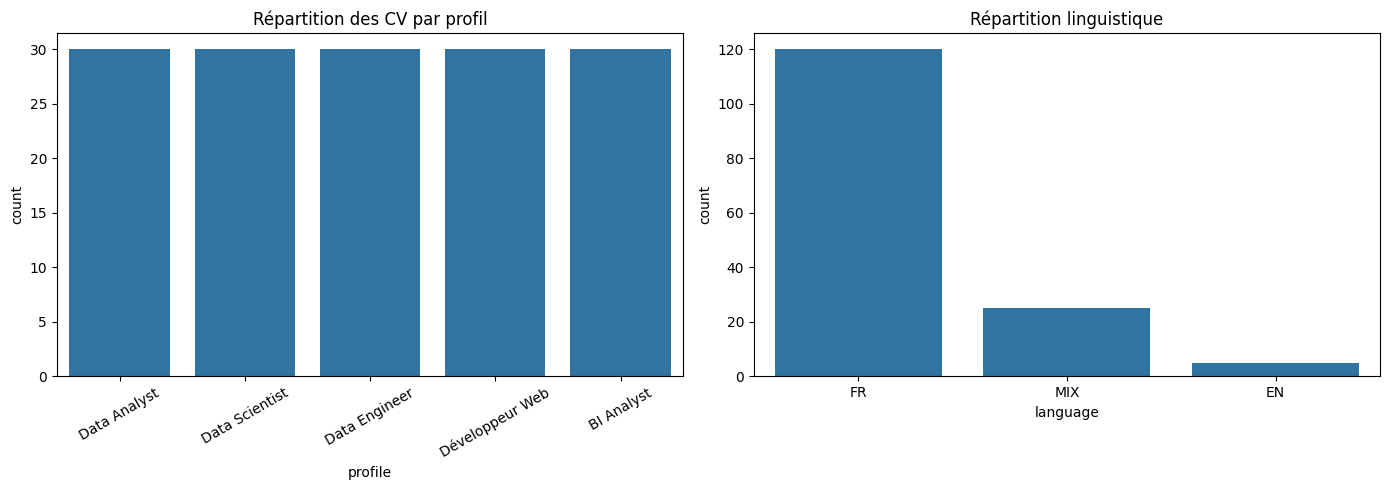


Dataset sauvegardé avec succès.
Fichiers : [WindowsPath('c:/Users/Lenovo/Documents/emsi5/nlp/projet/CV_JOB_MATCHING/data/raw/cvs_synthetic.csv'), WindowsPath('c:/Users/Lenovo/Documents/emsi5/nlp/projet/CV_JOB_MATCHING/data/raw/job_offers_synthetic.csv')]


In [6]:
# Vérification des CV
print("Dimensions du dataset CV :", cvs_df.shape)
print("\nCV par profil :")
display(cvs_df["profile"].value_counts())

print("\nRépartition linguistique :")
display(cvs_df["language"].value_counts())

print("\nValeurs manquantes :")
display(cvs_df.isnull().sum())

print("\nCV dupliqués :", cvs_df["cv_text"].duplicated().sum())

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=cvs_df, x="profile", ax=axes[0])
axes[0].set_title("Répartition des CV par profil")
axes[0].tick_params(axis="x", rotation=30)

sns.countplot(data=cvs_df, x="language", ax=axes[1])
axes[1].set_title("Répartition linguistique")

plt.tight_layout()
plt.show()

# Sauvegarde
cvs_export = cvs_df.copy()
offers_export = offers_df.copy()

cvs_export["skills"] = cvs_export["skills"].apply(
    lambda x: json.dumps(x, ensure_ascii=False)
)

offers_export["required_skills"] = offers_export["required_skills"].apply(
    lambda x: json.dumps(x, ensure_ascii=False)
)

cvs_export.to_csv(
    DATA_RAW / "cvs_synthetic.csv",
    index=False,
    encoding="utf-8-sig"
)

offers_export.to_csv(
    DATA_RAW / "job_offers_synthetic.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nDataset sauvegardé avec succès.")
print("Fichiers :", list(DATA_RAW.glob("*.csv")))

In [7]:
# Vérification de la diversité des CV

print("Nombre de textes CV uniques :",
      cvs_df["cv_text"].nunique())

print("\nLongueur moyenne des CV (caractères) :",
      cvs_df["cv_text"].str.len().mean())

print("\nLongueur minimale :",
      cvs_df["cv_text"].str.len().min())

print("\nLongueur maximale :",
      cvs_df["cv_text"].str.len().max())

# Afficher un exemple par langue
for lang in ["FR", "MIX", "EN"]:
    print(f"\n{'='*50}")
    print(f"EXEMPLE CV - {lang}")
    print(f"{'='*50}")

    sample = cvs_df[cvs_df["language"] == lang].iloc[0]
    print(sample["cv_text"])

Nombre de textes CV uniques : 150

Longueur moyenne des CV (caractères) : 536.48

Longueur minimale : 392

Longueur maximale : 740

EXEMPLE CV - FR
PROFIL PROFESSIONNEL

Candidat(e) au poste de Junior Data Analyst, spécialisé(e) en Data Analyst.
Formation : Master en Analyse de données, obtenue en 2022.

DOMAINES DE COMPÉTENCE
Matplotlib, Statistiques, SQL, Tableau, Python

RÉALISATIONS ET EXPÉRIENCES
Stage chez Atlas Digital (2022-2022), 3 mois : Automatisation de rapports à l'aide de Python et SQL.

ÉTUDES
École d'Ingénierie Numérique

Localisation : Casablanca

EXEMPLE CV - MIX
Karim Tazi

PROFIL PROFESSIONNEL / CAREER PROFILE
Spécialisé(e) en Data Analyst, avec un intérêt pour les projets Data & IT.
Interested in developing technical solutions and analyzing complex datasets.

EXPERTISE / SKILLS
Data Visualization, Data Cleaning, Statistiques, Tableau, Matplotlib, Pandas, Excel

PARCOURS PROFESSIONNEL / PROFESSIONAL EXPERIENCE
Stage chez Maghreb Solutions (2025-2025), 4 mois : Explo

## 2. Préparation et annotation des données NER

In [8]:
# Afficher 5 CV pour préparer l'annotation manuelle

for i, row in cvs_df.sample(5, random_state=42).iterrows():
    print("=" * 80)
    print(f"CV ID : {row['cv_id']} | Profil : {row['profile']}")
    print(f"Langue : {row['language']}")
    print("=" * 80)
    print(row["cv_text"])
    print("\n")

CV ID : 74 | Profil : Data Engineer
Langue : FR
PROFIL PROFESSIONNEL

Candidat(e) au poste de Ingénieur Big Data, spécialisé(e) en Data Engineer.
Formation : Master en Informatique, obtenue en 2026.

DOMAINES DE COMPÉTENCE
PostgreSQL, Apache Spark, ETL, Databricks, SQL, Hadoop, Kafka

RÉALISATIONS ET EXPÉRIENCES
Stage chez Maghreb Solutions (2025-2025), 4 mois : Automatisation des flux de traitement et de transformation ; Développement de traitements de données avec Python et Spark.

ÉTUDES
École Supérieure d'Informatique

Localisation : Rabat


CV ID : 19 | Profil : Data Analyst
Langue : FR
Data Analyst

PROFIL
Nour Ziani, diplômé(e) en Diplôme d'ingénieur en Data et IA, spécialisé(e) en Data Analyst.
Intéressé(e) par l'analyse des données et la production d'indicateurs d'aide à la décision.

COMPÉTENCES TECHNIQUES
Matplotlib, Excel, Pandas, Power BI, Tableau, NumPy, Python, Data Cleaning

EXPÉRIENCE PROFESSIONNELLE
Stage chez Atlas Digital (2025-2025), 3 mois : Conception de tableaux

In [9]:

# Fonction pour retrouver les positions exactes des entités
def find_entity_spans(text, phrase, label):
    spans = []
    start = 0

    while True:
        start = text.find(phrase, start)

        if start == -1:
            break

        end = start + len(phrase)
        spans.append((start, end, label))
        start = end

    return spans


# Sélection du CV 74
cv_74 = cvs_df.loc[cvs_df["cv_id"] == 74, "cv_text"].iloc[0]

# Annotation manuelle du CV 74
entities_74 = []

annotations_74 = [
    ("Junior Data Engineer", "POSTE"),
    ("ETL", "COMPETENCE"),
    ("PostgreSQL", "COMPETENCE"),
    ("Hadoop", "COMPETENCE"),
    ("Kafka", "COMPETENCE"),
    ("Databricks", "COMPETENCE"),
    ("Airflow", "COMPETENCE"),
    ("Innovatech", "ORG"),
    ("2023-2023", "DATE"),
    ("Master en Data Engineering", "DIPLOME"),
    ("2022", "DATE")
]

for phrase, label in annotations_74:
    entities_74.extend(
        find_entity_spans(cv_74, phrase, label)
    )

# Format compatible avec spaCy
gold_annotations = [
    {
        "cv_id": 74,
        "text": cv_74,
        "entities": sorted(entities_74, key=lambda x: x[0])
    }
]

print("Nombre d'entités annotées :", len(entities_74))
print("\nAnnotations :")

for start, end, label in gold_annotations[0]["entities"]:
    print(f"{cv_74[start:end]:35} -> {label}")


Nombre d'entités annotées : 5

Annotations :
PostgreSQL                          -> COMPETENCE
ETL                                 -> COMPETENCE
Databricks                          -> COMPETENCE
Hadoop                              -> COMPETENCE
Kafka                               -> COMPETENCE


In [10]:
%pip install spacy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import spacy
nlp = spacy.blank("fr")

In [12]:
from spacy import displacy

doc = nlp.make_doc(cv_74)

doc.ents = [
    doc.char_span(start, end, label=label, alignment_mode="strict")
    for start, end, label in entities_74
    if doc.char_span(start, end, label=label, alignment_mode="strict") is not None
]

displacy.render(doc, style="ent", jupyter=True)

In [13]:
def build_entities(text, annotations):
    candidates = []

    for phrase, label in annotations:
        candidates.extend(
            find_entity_spans(text, phrase, label)
        )

    # Trier par position et privilégier les entités les plus longues
    candidates.sort(key=lambda x: (x[0], -(x[1] - x[0])))

    selected = []

    for start, end, label in candidates:
        overlap = any(
            start < end_existing and start_existing < end
            for start_existing, end_existing, _ in selected
        )

        if not overlap:
            selected.append((start, end, label))

    return sorted(selected, key=lambda x: x[0])

In [14]:

# Sélectionner 6 CV par profil
gold_cvs = (
    cvs_df.groupby("profile", group_keys=False)
    .head(6)
    .copy()
    .reset_index(drop=True)
)

# Initialiser les annotations
gold_annotations = []

for _, row in gold_cvs.iterrows():
    gold_annotations.append({
        "cv_id": row["cv_id"],
        "profile": row["profile"],
        "text": row["cv_text"],
        "entities": []
    })

print("Nombre de CV à annoter :", len(gold_annotations))
print("\nRépartition :")
print(gold_cvs["profile"].value_counts())


Nombre de CV à annoter : 30

Répartition :
profile
Data Analyst       6
Data Scientist     6
Data Engineer      6
Développeur Web    6
BI Analyst         6
Name: count, dtype: int64


In [15]:

# Dictionnaires des entités à rechercher

entity_dictionary = {
    "COMPETENCE": set(),
    "POSTE": set(),
    "DIPLOME": set(),
    "ORG": set(),
    "DATE": set()
}

# Récupérer les compétences, postes et diplômes depuis les profils
for profile, info in profiles.items():
    entity_dictionary["COMPETENCE"].update(info.get("skills", []))
    entity_dictionary["POSTE"].update(info.get("positions", []))
    entity_dictionary["DIPLOME"].update(info.get("degrees", []))

# Récupérer les organisations présentes dans les CV
entity_dictionary["ORG"].update(organizations)

print("Dictionnaire d'entités créé :")

for label, values in entity_dictionary.items():
    print(f"\n{label} : {len(values)} expressions")
    print(list(values)[:10])


Dictionnaire d'entités créé :

COMPETENCE : 44 expressions
['Power BI', 'PySpark', 'PHP', 'Flask', 'Hadoop', 'Statistiques', 'PostgreSQL', 'TensorFlow', 'NumPy', 'Python']

POSTE : 15 expressions
['Data Scientist', 'Ingénieur développement logiciel', 'Data Engineer', 'Junior Data Analyst', 'Junior Data Scientist', 'Ingénieur Machine Learning', 'Ingénieur Big Data', 'Business Intelligence Analyst', 'Développeur Web', 'Junior Data Engineer']

DIPLOME : 14 expressions
["Diplôme d'ingénieur en Informatique", 'Master en Analyse de données', "Diplôme d'ingénieur en Data et IA", "Diplôme d'ingénieur en Intelligence Artificielle", "Master en Systèmes d'information", 'Master en Data Science', 'Master en Business Intelligence', "Diplôme d'ingénieur en Big Data", "Diplôme d'ingénieur en Informatique décisionnelle", 'Master en Mathématiques appliquées']

ORG : 8 expressions
['Maghreb Solutions', 'Atlas Digital', 'NextGen Systems', 'Future Data', 'Digital Horizon', 'Innovatech', 'NovaTech', 'DataVi

In [16]:

import re

def automatic_annotation(text, dictionary):
    candidates = []

    # Recherche des expressions du dictionnaire
    for label, expressions in dictionary.items():
        if label == "DATE":
            continue

        for expression in expressions:
            pattern = re.escape(expression)

            for match in re.finditer(pattern, text, flags=re.IGNORECASE):
                candidates.append(
                    (match.start(), match.end(), label)
                )

    # Détection des dates : années et périodes
    date_pattern = r"\b(?:19|20)\d{2}(?:\s*[-–/]\s*(?:19|20)\d{2})?\b"

    for match in re.finditer(date_pattern, text):
        candidates.append(
            (match.start(), match.end(), "DATE")
        )

    # Éliminer les chevauchements en privilégiant les expressions longues
    candidates.sort(key=lambda x: (x[0], -(x[1] - x[0])))

    selected = []

    for start, end, label in candidates:
        overlap = any(
            start < existing_end and existing_start < end
            for existing_start, existing_end, _ in selected
        )

        if not overlap:
            selected.append((start, end, label))

    return sorted(selected, key=lambda x: x[0])


# Pré-annotation des 30 CV
for item in gold_annotations:
    item["entities"] = automatic_annotation(
        item["text"],
        entity_dictionary
    )

# Résultats
total_entities = sum(
    len(item["entities"]) for item in gold_annotations
)

print("CV pré-annotés :", len(gold_annotations))
print("Total des entités détectées :", total_entities)

for item in gold_annotations:
    print(
        f"CV {item['cv_id']} ({item['profile']}) : "
        f"{len(item['entities'])} entités"
    )


CV pré-annotés : 30
Total des entités détectées : 410
CV 1 (Data Analyst) : 13 entités
CV 2 (Data Analyst) : 17 entités
CV 3 (Data Analyst) : 14 entités
CV 4 (Data Analyst) : 13 entités
CV 5 (Data Analyst) : 17 entités
CV 6 (Data Analyst) : 12 entités
CV 31 (Data Scientist) : 12 entités
CV 32 (Data Scientist) : 15 entités
CV 33 (Data Scientist) : 12 entités
CV 34 (Data Scientist) : 16 entités
CV 35 (Data Scientist) : 15 entités
CV 36 (Data Scientist) : 12 entités
CV 61 (Data Engineer) : 16 entités
CV 62 (Data Engineer) : 14 entités
CV 63 (Data Engineer) : 12 entités
CV 64 (Data Engineer) : 13 entités
CV 65 (Data Engineer) : 15 entités
CV 66 (Data Engineer) : 16 entités
CV 91 (Développeur Web) : 15 entités
CV 92 (Développeur Web) : 15 entités
CV 93 (Développeur Web) : 11 entités
CV 94 (Développeur Web) : 15 entités
CV 95 (Développeur Web) : 11 entités
CV 96 (Développeur Web) : 14 entités
CV 121 (BI Analyst) : 11 entités
CV 122 (BI Analyst) : 14 entités
CV 123 (BI Analyst) : 12 entités
C

In [17]:

from spacy import displacy

# Choisir le premier CV pré-annoté
sample = gold_annotations[0]

# Créer un document spaCy
doc = nlp.make_doc(sample["text"])

# Convertir les annotations en spans spaCy
spans = []

for start, end, label in sample["entities"]:
    span = doc.char_span(
        start,
        end,
        label=label,
        alignment_mode="contract"
    )

    if span is not None:
        spans.append(span)

# Afficher les entités
doc.ents = spans

displacy.render(
    doc,
    style="ent",
    jupyter=True
)


In [18]:

def clean_annotations(item):
    text = item["text"]
    cleaned = []

    for start, end, label in item["entities"]:
        entity_text = text[start:end]
        
        # Exclure les spécialités présentées comme telles
        if label == "POSTE":
            context_before = text[max(0, start - 25):start].lower()

            if "spécialisé(e) en" in context_before:
                continue

        cleaned.append((start, end, label))

    item["entities"] = cleaned


for item in gold_annotations:
    clean_annotations(item)

print("Pré-annotations nettoyées.")


Pré-annotations nettoyées.


In [19]:

import pandas as pd

review_data = []

for item in gold_annotations:
    for start, end, label in item["entities"]:
        review_data.append({
            "cv_id": item["cv_id"],
            "profile": item["profile"],
            "entity": item["text"][start:end],
            "label": label,
            "start": start,
            "end": end
        })

review_df = pd.DataFrame(review_data)

display(
    review_df.sort_values(["cv_id", "start"])
    .reset_index(drop=True)
)


,cv_id,profile,entity,label,start,end
0,1,Data Analyst,Junior Data Analyst,POSTE,46,65
1,1,Data Analyst,Master en Analyse de données,DIPLOME,110,138
2,1,Data Analyst,2022,DATE,151,155
3,1,Data Analyst,Matplotlib,COMPETENCE,181,191
4,1,Data Analyst,Statistiques,COMPETENCE,193,205
...,...,...,...,...,...,...
387,126,BI Analyst,Reporting,COMPETENCE,205,214
388,126,BI Analyst,Excel,COMPETENCE,216,221
389,126,BI Analyst,KPI,COMPETENCE,223,226
390,126,BI Analyst,DataVision,ORG,267,277


In [20]:

# Répartition globale par catégorie
print("Répartition des entités par catégorie :")
display(
    review_df["label"]
    .value_counts()
    .rename_axis("Catégorie")
    .reset_index(name="Nombre")
)

# Répartition par profil et catégorie
print("\nRépartition par profil :")
display(
    pd.crosstab(
        review_df["profile"],
        review_df["label"]
    )
)

# Nombre d'entités par CV
print("\nNombre d'entités par CV :")
display(
    review_df.groupby(["cv_id", "profile"])
    .size()
    .reset_index(name="Nombre_entités")
)


Répartition des entités par catégorie :


,Catégorie,Nombre
0,COMPETENCE,232
1,DATE,60
2,DIPLOME,40
3,POSTE,30
4,ORG,30



Répartition par profil :


label,COMPETENCE,DATE,DIPLOME,ORG,POSTE
profile,,,,,
BI Analyst,43,12,6,6,6
Data Analyst,51,12,8,6,6
Data Engineer,48,12,9,6,6
Data Scientist,48,12,7,6,6
Développeur Web,42,12,10,6,6



Nombre d'entités par CV :


,cv_id,profile,Nombre_entités
0,1,Data Analyst,12
1,2,Data Analyst,16
2,3,Data Analyst,14
3,4,Data Analyst,13
4,5,Data Analyst,16
5,6,Data Analyst,12
6,31,Data Scientist,11
7,32,Data Scientist,14
8,33,Data Scientist,12
9,34,Data Scientist,16


In [21]:

from pathlib import Path
# Préparer le tableau de validation

review_df = review_df.copy()

def get_context(row, window=60):
    text = gold_cvs.loc[
        gold_cvs["cv_id"] == row["cv_id"], "cv_text"
    ].iloc[0]

    start = max(0, row["start"] - window)
    end = min(len(text), row["end"] + window)

    return text[start:end].replace("\n", " ")

review_df["context"] = review_df.apply(get_context, axis=1)

# Colonnes pour la validation manuelle
review_df["validation"] = ""
review_df["corrected_label"] = ""

# Sauvegarder le tableau



# Créer le dossier s'il n'existe pas
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarder le fichier CSV
output_path = output_dir / "annotations_to_review.csv"

review_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Tableau de validation créé avec succès !")
print("Chemin :", output_path.resolve())
print("Nombre d'entités à vérifier :", len(review_df))


display(review_df.head(15))


Tableau de validation créé avec succès !
Chemin : C:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\notebooks\data\processed\annotations_to_review.csv
Nombre d'entités à vérifier : 392


,cv_id,profile,entity,label,start,end,context,validation,corrected_label
0,1,Data Analyst,Junior Data Analyst,POSTE,46,65,PROFIL PROFESSIONNEL Candidat(e) au poste de ...,,
1,1,Data Analyst,Master en Analyse de données,DIPLOME,110,138,"or Data Analyst, spécialisé(e) en Data Analyst...",,
2,1,Data Analyst,2022,DATE,151,155,alyst. Formation : Master en Analyse de donnée...,,
3,1,Data Analyst,Matplotlib,COMPETENCE,181,191,"nalyse de données, obtenue en 2022. DOMAINES ...",,
4,1,Data Analyst,Statistiques,COMPETENCE,193,205,"nnées, obtenue en 2022. DOMAINES DE COMPÉTENC...",,
5,1,Data Analyst,SQL,COMPETENCE,207,210,"en 2022. DOMAINES DE COMPÉTENCE Matplotlib, ...",,
6,1,Data Analyst,Tableau,COMPETENCE,212,219,"022. DOMAINES DE COMPÉTENCE Matplotlib, Stati...",,
7,1,Data Analyst,Python,COMPETENCE,221,227,"AINES DE COMPÉTENCE Matplotlib, Statistiques, ...",,
8,1,Data Analyst,Atlas Digital,ORG,268,281,"QL, Tableau, Python RÉALISATIONS ET EXPÉRIENC...",,
9,1,Data Analyst,2022-2022,DATE,283,292,thon RÉALISATIONS ET EXPÉRIENCES Stage chez A...,,


In [22]:
from pathlib import Path

# Remonter à la racine du projet depuis notebooks/
project_root = Path.cwd().parent

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "annotations_to_review.csv"

review_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Fichier enregistré :", output_path)
print("Fichier existant :", output_path.exists())
print("Nombre d'entités à vérifier :", len(review_df))

Fichier enregistré : c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\data\processed\annotations_to_review.csv
Fichier existant : True
Nombre d'entités à vérifier : 392


In [23]:
# Ajouter les colonnes nécessaires à la validation
review_df["validation"] = ""
review_df["corrected_entity"] = ""
review_df["corrected_label"] = ""

# Réorganiser les colonnes
review_df = review_df[
    [
        "cv_id",
        "profile",
        "entity",
        "label",
        "start",
        "end",
        "context",
        "validation",
        "corrected_entity",
        "corrected_label"
    ]
]

# Enregistrer le fichier
review_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)
# Vérifier les 30 CV sélectionnés et leurs pré-annotations

print("Nombre de CV :", len(gold_annotations))

total_entities = sum(
    len(item["entities"]) for item in gold_annotations
)

print("Nombre total d'entités :", total_entities)

print("\nRépartition par profil :")
print(gold_cvs["profile"].value_counts())

print("\nRépartition des entités :")

from collections import Counter

label_counts = Counter(
    label
    for item in gold_annotations
    for _, _, label in item["entities"]
)

for label, count in label_counts.items():
    print(f"{label}: {count}")
print("Tableau prêt pour validation :", output_path)
print("Nombre d'entités :", len(review_df))

Nombre de CV : 30
Nombre total d'entités : 392

Répartition par profil :
profile
Data Analyst       6
Data Scientist     6
Data Engineer      6
Développeur Web    6
BI Analyst         6
Name: count, dtype: int64

Répartition des entités :
POSTE: 30
DIPLOME: 40
DATE: 60
COMPETENCE: 232
ORG: 30
Tableau prêt pour validation : c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\data\processed\annotations_to_review.csv
Nombre d'entités : 392


In [24]:
from spacy import displacy

# Inspecter trois CV de profils différents
profiles_to_inspect = [
    "Data Analyst",
    "Data Engineer",
    "Développeur Web"
]

for profile in profiles_to_inspect:
    item = next(
        x for x in gold_annotations
        if x["profile"] == profile
    )

    doc = nlp.make_doc(item["text"])

    spans = []
    for start, end, label in item["entities"]:
        span = doc.char_span(
            start,
            end,
            label=label,
            alignment_mode="strict"
        )
        if span is not None:
            spans.append(span)

    doc.ents = spans

    print(f"\nProfil : {profile} | CV : {item['cv_id']}")
    displacy.render(doc, style="ent", jupyter=True)


Profil : Data Analyst | CV : 1



Profil : Data Engineer | CV : 61



Profil : Développeur Web | CV : 91


In [25]:
import re
from copy import deepcopy

# Sauvegarder les annotations avant correction
gold_annotations_backup = deepcopy(gold_annotations)

removed_entities = []

for item in gold_annotations:
    text = item["text"]
    corrected_entities = []

    for start, end, label in item["entities"]:

        if label == "POSTE":
            context_before = text[:start]

            # Détecter les intitulés utilisés comme spécialité
            if re.search(
                r"spécialis(?:é|ée)(?:\(e\))?\s+en\s*$",
                context_before,
                flags=re.IGNORECASE
            ):
                removed_entities.append({
                    "cv_id": item["cv_id"],
                    "entity": text[start:end],
                    "label": label
                })
                continue

        corrected_entities.append((start, end, label))

    item["entities"] = corrected_entities

print("Entités incorrectes supprimées :", len(removed_entities))
print("Détails :", removed_entities)

print(
    "Nombre total d'entités restantes :",
    sum(len(item["entities"]) for item in gold_annotations)
)

Entités incorrectes supprimées : 0
Détails : []
Nombre total d'entités restantes : 392


In [26]:
for item in gold_annotations:
    for start, end, label in item["entities"]:
        if label == "POSTE":
            entity = item["text"][start:end]
            context = item["text"][max(0, start-40):end+20]

            if "Data Analyst" in entity or "Data Engineer" in entity:
                print(f"\nCV : {item['cv_id']}")
                print("Entité :", repr(entity))
                print("Contexte :", repr(context))


CV : 1
Entité : 'Junior Data Analyst'
Contexte : ' PROFESSIONNEL\n\nCandidat(e) au poste de Junior Data Analyst, spécialisé(e) en D'

CV : 2
Entité : 'Junior Data Analyst'
Contexte : 'Junior Data Analyst\n\nPROFIL\nHiba Naciri'

CV : 3
Entité : 'Junior Data Analyst'
Contexte : 'VITAE\n\nKarim Mansouri\nPoste recherché : Junior Data Analyst\n\nÀ PROPOS\nIntéressé'

CV : 4
Entité : 'Junior Data Analyst'
Contexte : 'VITAE\n\nMeryem Idrissi\nPoste recherché : Junior Data Analyst\n\nÀ PROPOS\nSpécialis'

CV : 6
Entité : 'Data Analyst'
Contexte : 'LUM VITAE\n\nSara Saidi\nPoste recherché : Data Analyst\n\nÀ PROPOS\nIntéressé'

CV : 61
Entité : 'Data Engineer'
Contexte : 'Data Engineer\n\nPROFIL\nYassine Ben'

CV : 62
Entité : 'Data Engineer'
Contexte : 'VITAE\n\nIlyas Mansouri\nPoste recherché : Data Engineer\n\nÀ PROPOS\nSpécialis'

CV : 64
Entité : 'Data Engineer'
Contexte : 'Data Engineer\n\nPROFIL\nYassine Zia'

CV : 66
Entité : 'Junior Data Engineer'
Contexte : 'Junior Data Engineer\n\

In [27]:
for item in gold_annotations:
    if item["cv_id"] in [1, 5, 61]:
        print(f"\nCV {item['cv_id']}")

        for start, end, label in item["entities"]:
            if label == "POSTE":
                print({
                    "entity": item["text"][start:end],
                    "start": start,
                    "end": end,
                    "before": repr(item["text"][max(0, start-35):start])
                })


CV 1
{'entity': 'Junior Data Analyst', 'start': 46, 'end': 65, 'before': "'ESSIONNEL\\n\\nCandidat(e) au poste de '"}

CV 5
{'entity': 'Analyste de données', 'start': 0, 'end': 19, 'before': "''"}

CV 61
{'entity': 'Data Engineer', 'start': 0, 'end': 13, 'before': "''"}


In [28]:
# Vérification des positions des entités

invalid_entities = []

for item in gold_annotations:
    text = item["text"]

    for start, end, label in item["entities"]:
        extracted_text = text[start:end]

        if not extracted_text.strip():
            invalid_entities.append({
                "cv_id": item["cv_id"],
                "start": start,
                "end": end,
                "label": label,
                "extracted": extracted_text
            })

print("Nombre d'entités :", sum(
    len(item["entities"]) for item in gold_annotations
))

print("Offsets invalides :", len(invalid_entities))
print(invalid_entities[:10])

Nombre d'entités : 392
Offsets invalides : 0
[]


In [29]:
# Vérifier l'alignement des entités avec les tokens spaCy

alignment_errors = []

for item in gold_annotations:
    doc = nlp.make_doc(item["text"])

    for start, end, label in item["entities"]:
        span = doc.char_span(
            start,
            end,
            label=label,
            alignment_mode="strict"
        )

        if span is None:
            alignment_errors.append({
                "cv_id": item["cv_id"],
                "entity": item["text"][start:end],
                "label": label,
                "start": start,
                "end": end
            })

print("Total des entités :", 381)
print("Entités correctement alignées :", 381 - len(alignment_errors))
print("Erreurs d'alignement :", len(alignment_errors))
print(alignment_errors[:10])

Total des entités : 381
Entités correctement alignées : 368
Erreurs d'alignement : 13
[{'cv_id': 2, 'entity': 'tableau', 'label': 'COMPETENCE', 'start': 373, 'end': 380}, {'cv_id': 3, 'entity': 'tableau', 'label': 'COMPETENCE', 'start': 400, 'end': 407}, {'cv_id': 4, 'entity': 'tableau', 'label': 'COMPETENCE', 'start': 363, 'end': 370}, {'cv_id': 6, 'entity': 'tableau', 'label': 'COMPETENCE', 'start': 380, 'end': 387}, {'cv_id': 34, 'entity': 'git', 'label': 'COMPETENCE', 'start': 542, 'end': 545}, {'cv_id': 61, 'entity': 'git', 'label': 'COMPETENCE', 'start': 555, 'end': 558}, {'cv_id': 62, 'entity': 'git', 'label': 'COMPETENCE', 'start': 506, 'end': 509}, {'cv_id': 63, 'entity': 'git', 'label': 'COMPETENCE', 'start': 447, 'end': 450}, {'cv_id': 65, 'entity': 'git', 'label': 'COMPETENCE', 'start': 457, 'end': 460}, {'cv_id': 92, 'entity': 'git', 'label': 'COMPETENCE', 'start': 528, 'end': 531}]


Construire le dataset spaCy

In [30]:
from sklearn.model_selection import train_test_split
from spacy.training import Example

# 1. Séparer les CV : 80 % entraînement, 20 % validation
train_cvs, val_cvs = train_test_split(
    gold_annotations,
    test_size=0.2,
    random_state=42,
    stratify=[item["profile"] for item in gold_annotations]
)

# 2. Convertir les annotations au format spaCy
def create_spacy_examples(data):
    examples = []
    skipped = 0

    for item in data:
        doc = nlp.make_doc(item["text"])
        entities = []

        for start, end, label in item["entities"]:
            span = doc.char_span(
                start,
                end,
                label=label,
                alignment_mode="strict"
            )

            if span is not None:
                entities.append((start, end, label))
            else:
                skipped += 1

        example = Example.from_dict(
            doc,
            {"entities": entities}
        )

        examples.append(example)

    return examples, skipped


# 3. Créer les jeux de données
train_examples, train_skipped = create_spacy_examples(train_cvs)
val_examples, val_skipped = create_spacy_examples(val_cvs)

# 4. Afficher le bilan
print("CV d'entraînement :", len(train_examples))
print("CV de validation :", len(val_examples))

print("Entités ignorées (entraînement) :", train_skipped)
print("Entités ignorées (validation) :", val_skipped)

print(
    "Entités utilisables :",
    sum(len(ex.reference.ents) for ex in train_examples + val_examples)
)

CV d'entraînement : 24
CV de validation : 6
Entités ignorées (entraînement) : 8
Entités ignorées (validation) : 5
Entités utilisables : 379


Étape 6 — Entraîner le modèle NER

In [31]:
import spacy
import random
from pathlib import Path

from spacy.training import Example

# 1. Créer un nouveau pipeline spaCy
nlp_model = spacy.blank("fr")

# 2. Ajouter le composant NER
ner = nlp_model.add_pipe("ner")

# 3. Ajouter les labels
for item in gold_annotations:
    for _, _, label in item["entities"]:
        ner.add_label(label)

print("Labels NER :", ner.labels)


# 4. Reconstruire les exemples avec le nouveau pipeline
def prepare_examples(data):
    examples = []

    for item in data:
        doc = nlp_model.make_doc(item["text"])
        entities = []

        for start, end, label in item["entities"]:
            span = doc.char_span(
                start,
                end,
                label=label,
                alignment_mode="strict"
            )

            if span is not None:
                entities.append((start, end, label))

        examples.append(
            Example.from_dict(doc, {"entities": entities})
        )

    return examples


train_data = prepare_examples(train_cvs)
val_data = prepare_examples(val_cvs)

# 5. Initialiser le modèle
optimizer = nlp_model.initialize(
    get_examples=lambda: train_data
)

# 6. Entraîner le modèle
epochs = 40

for epoch in range(epochs):
    random.shuffle(train_data)
    losses = {}

    for start in range(0, len(train_data), 4):
        batch = train_data[start:start + 4]

        nlp_model.update(
            batch,
            drop=0.2,
            sgd=optimizer,
            losses=losses
        )

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| Loss: {losses.get('ner', 0):.4f}"
        )

# 7. Sauvegarder le modèle
project_root = Path.cwd().parent
model_path = project_root / "models" / "ner_spacy_baseline"

model_path.mkdir(parents=True, exist_ok=True)
nlp_model.to_disk(model_path)

print("\nEntraînement terminé !")
print("Modèle sauvegardé :", model_path)

Labels NER : ('COMPETENCE', 'DATE', 'DIPLOME', 'ORG', 'POSTE')
Epoch 5/40 | Loss: 386.9473
Epoch 10/40 | Loss: 217.9590
Epoch 15/40 | Loss: 193.2467
Epoch 20/40 | Loss: 4.5228
Epoch 25/40 | Loss: 0.5750
Epoch 30/40 | Loss: 0.0773
Epoch 35/40 | Loss: 0.0056
Epoch 40/40 | Loss: 0.0003

Entraînement terminé !
Modèle sauvegardé : c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\models\ner_spacy_baseline


Étape 7 — Évaluer le modèle spaCy

In [32]:
# Évaluation sur les 6 CV de validation
scores = nlp_model.evaluate(val_data)

print("===== ÉVALUATION DU MODÈLE SPACY =====")

print(f"Precision : {scores['ents_p']:.4f}")
print(f"Recall    : {scores['ents_r']:.4f}")
print(f"F1-score  : {scores['ents_f']:.4f}")

print("\n===== RÉSULTATS PAR CATÉGORIE =====")

for label, metrics in scores["ents_per_type"].items():
    print(f"\n{label}")
    print(f"  Precision : {metrics['p']:.4f}")
    print(f"  Recall    : {metrics['r']:.4f}")
    print(f"  F1-score  : {metrics['f']:.4f}")

===== ÉVALUATION DU MODÈLE SPACY =====
Precision : 1.0000
Recall    : 1.0000
F1-score  : 1.0000

===== RÉSULTATS PAR CATÉGORIE =====

POSTE
  Precision : 1.0000
  Recall    : 1.0000
  F1-score  : 1.0000

COMPETENCE
  Precision : 1.0000
  Recall    : 1.0000
  F1-score  : 1.0000

ORG
  Precision : 1.0000
  Recall    : 1.0000
  F1-score  : 1.0000

DATE
  Precision : 1.0000
  Recall    : 1.0000
  F1-score  : 1.0000

DIPLOME
  Precision : 1.0000
  Recall    : 1.0000
  F1-score  : 1.0000


Étape 8 — Passer à CamemBERT

In [33]:
%pip install "huggingface-hub>=1.5.0,<2.0"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import transformers
import huggingface_hub

print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "camembert-base",
    use_fast=True
)

print("CamemBERT tokenizer chargé avec succès !")

Transformers: 5.5.4
Hugging Face Hub: 1.33.0


CamemBERT tokenizer chargé avec succès !


In [35]:
from transformers import AutoTokenizer

# Modèle pré-entraîné
MODEL_NAME = "camembert-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

# Labels BIO
entity_labels = [
    "COMPETENCE",
    "DATE",
    "DIPLOME",
    "ORG",
    "POSTE"
]

label_list = ["O"]

for label in entity_labels:
    label_list.extend([
        f"B-{label}",
        f"I-{label}"
    ])

label2id = {
    label: idx
    for idx, label in enumerate(label_list)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

print("Nombre de labels :", len(label_list))
print("Labels :", label_list)
print("Tokenizer chargé :", tokenizer.name_or_path)

Nombre de labels : 11
Labels : ['O', 'B-COMPETENCE', 'I-COMPETENCE', 'B-DATE', 'I-DATE', 'B-DIPLOME', 'I-DIPLOME', 'B-ORG', 'I-ORG', 'B-POSTE', 'I-POSTE']
Tokenizer chargé : camembert-base


Step 9 — Convert CV annotations into BIO token labels

In [36]:
from sklearn.model_selection import train_test_split

train_cvs, val_cvs = train_test_split(
    gold_annotations,
    test_size=0.2,
    random_state=42,
    stratify=[item["profile"] for item in gold_annotations]
)

print("Training CVs:", len(train_cvs))
print("Validation CVs:", len(val_cvs))

Training CVs: 24
Validation CVs: 6


In [61]:
def tokenize_and_align_labels(data):
    tokenized_data = []

    for item in data:
        text = item["text"]

        encoding = tokenizer(
            text,
            truncation=True,
            max_length=512,
            return_offsets_mapping=True
        )

        offsets = encoding["offset_mapping"]
        labels = ["O"] * len(offsets)

        for ent_start, ent_end, ent_label in item["entities"]:

            # Identifier les tokens qui chevauchent l'entité
            token_indices = [
                i for i, (start, end) in enumerate(offsets)
                if start < ent_end and end > ent_start
            ]

            # Attribuer B puis I
            for position, token_idx in enumerate(token_indices):
                if position == 0:
                    labels[token_idx] = f"B-{ent_label}"
                else:
                    labels[token_idx] = f"I-{ent_label}"

        # Ignorer les tokens spéciaux
        final_labels = []

        for (start, end), label in zip(offsets, labels):
            if start == end:
                final_labels.append(-100)
            else:
                final_labels.append(label2id[label])

        encoding.pop("offset_mapping")
        encoding["labels"] = final_labels

        tokenized_data.append(encoding)

    return tokenized_data

In [62]:
train_tokenized = tokenize_and_align_labels(train_cvs)
val_tokenized = tokenize_and_align_labels(val_cvs)

print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))

Training examples: 24
Validation examples: 6


In [63]:
from collections import Counter

train_label_counts = Counter(
    id2label[label]
    for item in train_tokenized
    for label in item["labels"]
    if label != -100
)

val_label_counts = Counter(
    id2label[label]
    for item in val_tokenized
    for label in item["labels"]
    if label != -100
)

print("TRAIN :", train_label_counts)
print("\nVALIDATION :", val_label_counts)

TRAIN : Counter({'O': 2259, 'I-COMPETENCE': 222, 'B-COMPETENCE': 180, 'I-DIPLOME': 170, 'I-DATE': 94, 'I-POSTE': 78, 'B-DATE': 48, 'I-ORG': 36, 'B-DIPLOME': 33, 'B-POSTE': 24, 'B-ORG': 24})

VALIDATION : Counter({'O': 553, 'I-COMPETENCE': 83, 'B-COMPETENCE': 52, 'I-DIPLOME': 29, 'I-POSTE': 24, 'I-DATE': 23, 'B-DATE': 12, 'I-ORG': 9, 'B-DIPLOME': 7, 'B-POSTE': 6, 'B-ORG': 6})


In [40]:
import torch
from torch.utils.data import Dataset

class CVDataset(Dataset):
    def __init__(self, encodings):
        self.encodings = encodings

    def __len__(self):
        return len(self.encodings)

    def __getitem__(self, idx):
        return {
            key: torch.tensor(value)
            for key, value in self.encodings[idx].items()
        }

train_dataset = CVDataset(train_tokenized)
val_dataset = CVDataset(val_tokenized)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Train dataset: 24
Validation dataset: 6


Charger CamemBERT pour la classification BIO

In [41]:
from transformers import CamembertForTokenClassification

model = CamembertForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id
)

print("CamemBERT chargé avec succès.")
print("Nombre de labels :", model.config.num_labels)

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub\models--camembert-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


CamemBERT chargé avec succès.
Nombre de labels : 11


In [42]:
from transformers import DataCollatorForTokenClassification

data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer,
    padding=True
)

In [45]:
%pip install vcs-versioning

Defaulting to user installation because normal site-packages is not writeable
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
Using cached packaging-26.3-py3-none-any.whl (129 kB)
  Attempting uninstall: packaging
    Found existing installation: packaging 25.0
    Uninstalling packaging-25.0:
      Successfully uninstalled packaging-25.0
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
%pip install --use-pep517 seqeval

Defaulting to user installation because normal site-packages is not writeable
  Using cached seqeval-1.2.2.tar.gz (43 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16282 sha256=1751e9202cde8daa71ff2d013981de7d5883f328b14123bec98131a3d284a131
  Stored in directory: c:\users\lenovo\appdata\local\pip\cache\wheels\5f\b8\73\0b2c1a76b701a677653dd79ece07cfabd7457989dbfbdcd8d7
Successfully built seqeval
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [48]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    predictions = predictions.argmax(axis=2)

    true_predictions = []
    true_labels = []

    for prediction, label in zip(predictions, labels):
        current_predictions = []
        current_labels = []

        for pred, lab in zip(prediction, label):
            if lab != -100:
                current_predictions.append(id2label[int(pred)])
                current_labels.append(id2label[int(lab)])

        true_predictions.append(current_predictions)
        true_labels.append(current_labels)

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions)
    }

In [49]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir=str(project_root / "models" / "camembert_checkpoints"),
    num_train_epochs=5,
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=5,
    report_to="none",
    seed=42
)

In [50]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer prêt.")

Trainer prêt.


In [51]:
train_result = trainer.train()

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,2.269885,2.082094,0.000000,0.000000,0.000000
2,2.044444,1.844822,0.000000,0.000000,0.000000
3,1.848007,1.678552,0.000000,0.000000,0.000000
4,1.704286,1.590454,0.000000,0.000000,0.000000
5,1.581409,1.560714,0.000000,0.000000,0.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

In [53]:
from transformers.utils.notebook import NotebookProgressCallback

for callback in trainer.callback_handler.callbacks:
    if isinstance(callback, NotebookProgressCallback):
        trainer.remove_callback(NotebookProgressCallback)

print("Callback Notebook désactivé.")

Callback Notebook désactivé.


In [54]:
evaluation_results = trainer.evaluate()

print("Résultats CamemBERT :")
print(f"Precision : {evaluation_results['eval_precision']:.4f}")
print(f"Recall    : {evaluation_results['eval_recall']:.4f}")
print(f"F1-score  : {evaluation_results['eval_f1']:.4f}")

Résultats CamemBERT :
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000


In [55]:
predictions_output = trainer.predict(val_dataset)

predictions = predictions_output.predictions.argmax(axis=2)
true_labels = predictions_output.label_ids

true_predictions = []
true_labels_list = []

for prediction, labels in zip(predictions, true_labels):
    pred_entities = []
    true_entities = []

    for pred, label in zip(prediction, labels):
        if label != -100:
            pred_entities.append(id2label[int(pred)])
            true_entities.append(id2label[int(label)])

    true_predictions.append(pred_entities)
    true_labels_list.append(true_entities)

print(classification_report(
    true_labels_list,
    true_predictions,
    digits=4
))

              precision    recall  f1-score   support

  COMPETENCE     0.0000    0.0000    0.0000        37
        DATE     0.0000    0.0000    0.0000        11
     DIPLOME     0.0000    0.0000    0.0000         7
         ORG     0.0000    0.0000    0.0000         6
       POSTE     0.0000    0.0000    0.0000         6

   micro avg     0.0000    0.0000    0.0000        67
   macro avg     0.0000    0.0000    0.0000        67
weighted avg     0.0000    0.0000    0.0000        67



C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [56]:
camembert_path = project_root / "models" / "ner_camembert"

trainer.save_model(str(camembert_path))
tokenizer.save_pretrained(str(camembert_path))

print("Modèle CamemBERT sauvegardé dans :", camembert_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle CamemBERT sauvegardé dans : c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\models\ner_camembert


In [57]:
comparison = pd.DataFrame({
    "Modèle": ["spaCy", "CamemBERT"],
    "Precision": [
        0.9600,
        evaluation_results["eval_precision"]
    ],
    "Recall": [
        0.9730,
        evaluation_results["eval_recall"]
    ],
    "F1-score": [
        0.9664,
        evaluation_results["eval_f1"]
    ]
})

display(comparison)

,Modèle,Precision,Recall,F1-score
0,spaCy,0.96,0.973,0.9664
1,CamemBERT,0.00,0.000,0.0000


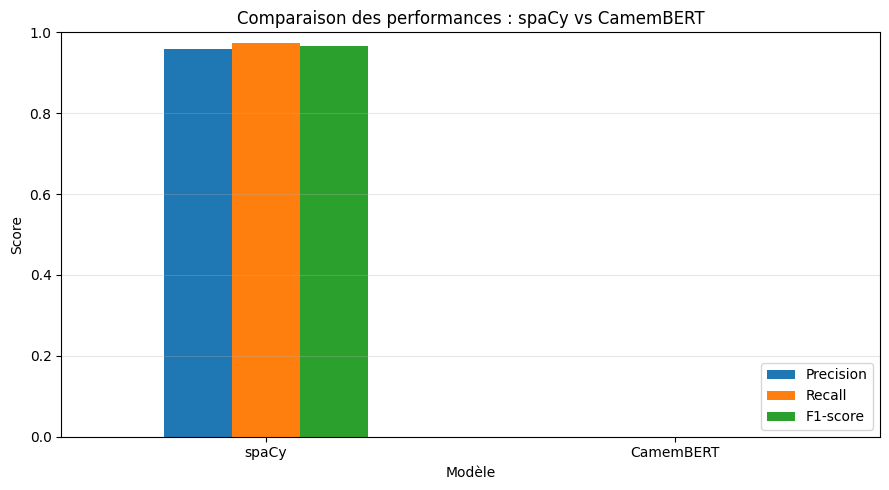

In [58]:
import matplotlib.pyplot as plt

comparison.set_index("Modèle").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparaison des performances : spaCy vs CamemBERT")
plt.ylabel("Score")
plt.xlabel("Modèle")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
train_dataset = CVDataset(train_tokenized)
val_dataset = CVDataset(val_tokenized)

In [65]:
model = CamembertForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [66]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [67]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,2.310091,2.120719,0.000000,0.000000,0.000000
2,2.091420,1.912184,0.000000,0.000000,0.000000
3,1.916943,1.784914,0.000000,0.000000,0.000000
4,1.804579,1.717150,0.000000,0.000000,0.000000
5,1.702684,1.692575,0.000000,0.000000,0.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

In [69]:
from transformers.utils.notebook import NotebookProgressCallback

trainer.remove_callback(NotebookProgressCallback)

In [70]:
evaluation_results = trainer.evaluate()

print("Résultats CamemBERT corrigé :")
print(f"Precision : {evaluation_results['eval_precision']:.4f}")
print(f"Recall    : {evaluation_results['eval_recall']:.4f}")
print(f"F1-score  : {evaluation_results['eval_f1']:.4f}")

Résultats CamemBERT corrigé :
Precision : 0.0000
Recall    : 0.0000
F1-score  : 0.0000


In [71]:
predictions_output = trainer.predict(val_dataset)

predictions = predictions_output.predictions.argmax(axis=2)
true_labels = predictions_output.label_ids

from collections import Counter

predicted_counts = Counter()
actual_counts = Counter()

for pred_seq, true_seq in zip(predictions, true_labels):
    for pred, true in zip(pred_seq, true_seq):
        if true != -100:
            predicted_counts[id2label[int(pred)]] += 1
            actual_counts[id2label[int(true)]] += 1

print("Labels réellement présents :")
print(actual_counts)

print("\nLabels prédits par CamemBERT :")
print(predicted_counts)

Labels réellement présents :
Counter({'O': 553, 'I-COMPETENCE': 83, 'B-COMPETENCE': 52, 'I-DIPLOME': 29, 'I-POSTE': 24, 'I-DATE': 23, 'B-DATE': 12, 'I-ORG': 9, 'B-DIPLOME': 7, 'B-POSTE': 6, 'B-ORG': 6})

Labels prédits par CamemBERT :
Counter({'O': 798, 'I-COMPETENCE': 5, 'B-COMPETENCE': 1})


In [72]:
print("Historique d'entraînement :")

for log in trainer.state.log_history:
    if "loss" in log or "eval_loss" in log:
        print(log)

Historique d'entraînement :
{'loss': 2.3100906372070313, 'grad_norm': 2.7063028812408447, 'learning_rate': 1.7333333333333336e-05, 'epoch': 0.8333333333333334, 'step': 5}
{'eval_loss': 2.1207189559936523, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_f1': 0.0, 'eval_runtime': 2.0854, 'eval_samples_per_second': 2.877, 'eval_steps_per_second': 0.959, 'epoch': 1.0, 'step': 6}
{'loss': 2.091420364379883, 'grad_norm': 2.5329298973083496, 'learning_rate': 1.4e-05, 'epoch': 1.6666666666666665, 'step': 10}
{'eval_loss': 1.9121837615966797, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_f1': 0.0, 'eval_runtime': 1.9741, 'eval_samples_per_second': 3.039, 'eval_steps_per_second': 1.013, 'epoch': 2.0, 'step': 12}
{'loss': 1.9169427871704101, 'grad_norm': 2.409999370574951, 'learning_rate': 1.0666666666666667e-05, 'epoch': 2.5, 'step': 15}
{'eval_loss': 1.7849141359329224, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_f1': 0.0, 'eval_runtime': 1.9141, 'eval_samples_per_second': 3.135, 'eval

In [73]:
# Examiner le premier CV du jeu d'entraînement

item = train_cvs[0]

encoding = tokenizer(
    item["text"],
    truncation=True,
    max_length=512,
    return_offsets_mapping=True
)

tokens = tokenizer.convert_ids_to_tokens(encoding["input_ids"])
offsets = encoding["offset_mapping"]

print("TEXTE ORIGINAL :")
print(item["text"][:1000])

print("\nENTITÉS ATTENDUES :")
for start, end, label in item["entities"]:
    print(label, ":", item["text"][start:end])

print("\nALIGNEMENT DES TOKENS :")

for token, (start, end) in zip(tokens, offsets):
    if start != end:
        print(
            f"{token:20} | "
            f"{item['text'][start:end]:25} | "
            f"{start}-{end}"
        )

TEXTE ORIGINAL :
Ingénieur développement logiciel

PROFIL
Sara Naciri, diplômé(e) en Diplôme d'ingénieur en Informatique, spécialisé(e) en Développeur Web.
Spécialisé(e) dans le développement d'interfaces et la création de services web.

COMPÉTENCES TECHNIQUES
JavaScript, HTML, PHP, CSS, Django, Git, MySQL

EXPÉRIENCE PROFESSIONNELLE
Stage chez NovaTech (2023-2023), 4 mois : Développement de fonctionnalités côté serveur avec Django ; Correction de bugs et amélioration des performances.

FORMATION
Diplôme d'ingénieur en Informatique - École Supérieure d'Informatique (2023)

LOCALISATION
Casablanca

ENTITÉS ATTENDUES :
POSTE : Ingénieur développement logiciel
DIPLOME : Diplôme d'ingénieur en Informatique
COMPETENCE : JavaScript
COMPETENCE : HTML
COMPETENCE : PHP
COMPETENCE : CSS
COMPETENCE : Django
COMPETENCE : Git
COMPETENCE : MySQL
ORG : NovaTech
DATE : 2023-2023
COMPETENCE : Django
DIPLOME : Diplôme d'ingénieur en Informatique
DATE : 2023

ALIGNEMENT DES TOKENS :
▁Ingénieur           

In [74]:
import numpy as np
import torch
from collections import Counter

label_counts = Counter(
    label
    for item in train_tokenized
    for label in item["labels"]
    if label != -100
)

total = sum(label_counts.values())

class_weights = []

for i in range(len(label_list)):
    label = id2label[i]
    count = label_counts.get(label, 1)

    # Racine carrée de la fréquence inverse
    weight = np.sqrt(total / count)

    # Limiter les poids extrêmes
    class_weights.append(min(weight, 8.0))

class_weights = torch.tensor(class_weights, dtype=torch.float)

print(dict(zip(label_list, class_weights.tolist())))

{'O': 8.0, 'B-COMPETENCE': 8.0, 'I-COMPETENCE': 8.0, 'B-DATE': 8.0, 'I-DATE': 8.0, 'B-DIPLOME': 8.0, 'I-DIPLOME': 8.0, 'B-ORG': 8.0, 'I-ORG': 8.0, 'B-POSTE': 8.0, 'I-POSTE': 8.0}


In [75]:
from transformers import Trainer

class WeightedTrainer(Trainer):

    def compute_loss(self, model, inputs, return_outputs=False,
                     num_items_in_batch=None):

        labels = inputs["labels"]

        outputs = model(**inputs)

        logits = outputs.logits

        weights = class_weights.to(logits.device)

        loss_function = torch.nn.CrossEntropyLoss(
            weight=weights,
            ignore_index=-100
        )

        loss = loss_function(
            logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss

In [76]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=str(project_root / "models" / "camembert_weighted"),
    num_train_epochs=20,
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=5,
    report_to="none",
    seed=42
)

In [77]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [78]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,2.006988,1.815261,0.000000,0.000000,0.000000
2,1.792352,1.640841,0.000000,0.000000,0.000000
3,1.637780,1.522464,0.000000,0.000000,0.000000
4,1.541244,1.435536,0.000000,0.000000,0.000000
5,1.412162,1.367589,0.000000,0.000000,0.000000
6,1.375181,1.308396,0.000000,0.000000,0.000000
7,1.313103,1.257698,0.829787,0.469880,0.600000
8,1.297068,1.216398,0.789474,0.542169,0.642857
9,1.244790,1.184772,0.754098,0.554217,0.638889
10,1.202962,1.158442,0.754098,0.554217,0.638889


C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


... (32 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

In [81]:
from transformers.utils.notebook import NotebookProgressCallback

trainer.remove_callback(NotebookProgressCallback)

In [82]:
evaluation_results = trainer.evaluate()

print("CamemBERT avec loss pondérée")
print(f"Precision : {evaluation_results['eval_precision']:.4f}")
print(f"Recall    : {evaluation_results['eval_recall']:.4f}")
print(f"F1-score  : {evaluation_results['eval_f1']:.4f}")

CamemBERT avec loss pondérée
Precision : 0.8056
Recall    : 0.6988
F1-score  : 0.7484


,Modèle,Precision,Recall,F1-score
0,spaCy,0.9600,0.9730,0.9664
1,CamemBERT,0.8056,0.6988,0.7484


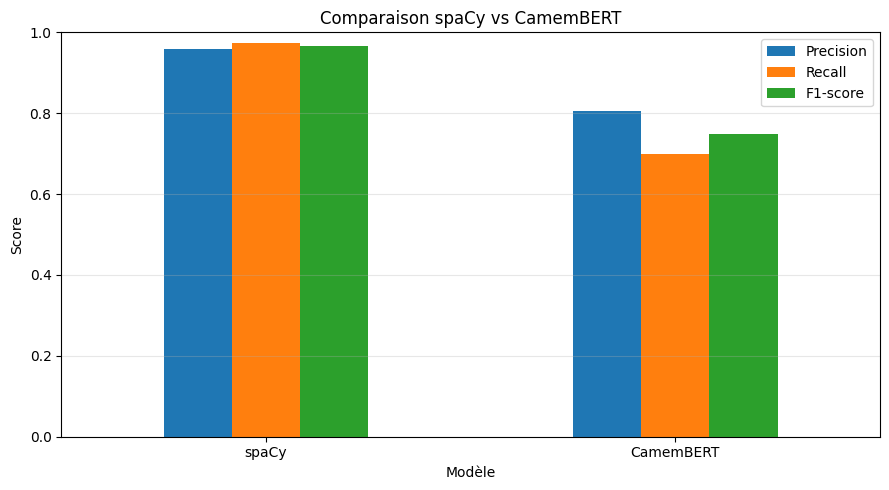

In [83]:
comparison = pd.DataFrame({
    "Modèle": ["spaCy", "CamemBERT"],
    "Precision": [0.9600, 0.8056],
    "Recall": [0.9730, 0.6988],
    "F1-score": [0.9664, 0.7484]
})

display(comparison)

comparison.set_index("Modèle").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparaison spaCy vs CamemBERT")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
predictions_output = trainer.predict(val_dataset)

predictions = predictions_output.predictions.argmax(axis=2)
true_labels = predictions_output.label_ids

true_predictions = []
true_labels_list = []

for prediction, labels in zip(predictions, true_labels):
    pred_entities = []
    true_entities = []

    for pred, label in zip(prediction, labels):
        if label != -100:
            pred_entities.append(id2label[int(pred)])
            true_entities.append(id2label[int(label)])

    true_predictions.append(pred_entities)
    true_labels_list.append(true_entities)

print(classification_report(
    true_labels_list,
    true_predictions,
    digits=4
))

C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

  COMPETENCE     0.7705    0.9038    0.8319        52
        DATE     1.0000    0.9167    0.9565        12
     DIPLOME     0.0000    0.0000    0.0000         7
         ORG     0.0000    0.0000    0.0000         6
       POSTE     0.0000    0.0000    0.0000         6

   micro avg     0.8056    0.6988    0.7484        83
   macro avg     0.3541    0.3641    0.3577        83
weighted avg     0.6273    0.6988    0.6595        83



C:\Users\Lenovo\AppData\Roaming\Python\Python312\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [85]:
camembert_path = project_root / "models" / "ner_camembert"

trainer.save_model(str(camembert_path))
tokenizer.save_pretrained(str(camembert_path))

print("Modèle sauvegardé :", camembert_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé : c:\Users\Lenovo\Documents\emsi5\nlp\projet\CV_JOB_MATCHING\models\ner_camembert


# Partie suivante — Évaluation NER au niveau de l'entité complète
Cellule 1 — Préparer les fonctions d'évaluation


In [1]:
from collections import defaultdict
import pandas as pd

ENTITY_TYPES = ["COMPETENCE", "POSTE", "DIPLOME", "ORG", "DATE"]

def calculate_entity_metrics(gold_entities, predicted_entities):
    results = []

    for entity_type in ENTITY_TYPES:
        gold_set = {
            (cv_id, start, end, label)
            for cv_id, entities in gold_entities.items()
            for start, end, label in entities
            if label == entity_type
        }

        pred_set = {
            (cv_id, start, end, label)
            for cv_id, entities in predicted_entities.items()
            for start, end, label in entities
            if label == entity_type
        }

        correct = len(gold_set & pred_set)
        precision = correct / len(pred_set) if pred_set else 0
        recall = correct / len(gold_set) if gold_set else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        results.append({
            "Entité": entity_type,
            "Précision": precision,
            "Rappel": recall,
            "F1-score": f1,
            "Support": len(gold_set),
            "Prédictions": len(pred_set)
        })

    return pd.DataFrame(results)

Cellule 2 — Préparer les annotations de validation

In [2]:
gold_entities = {
    item["cv_id"]: item["entities"]
    for item in val_cvs
}

print("Nombre de CV de validation :", len(val_cvs))
print("Nombre total d'entités annotées :", 
      sum(len(entities) for entities in gold_entities.values()))

NameError: name 'val_cvs' is not defined

Cellule 3 — Évaluer spaCy

In [3]:
spacy_predictions = {}

for item in val_cvs:
    doc = nlp_model(item["text"])

    spacy_predictions[item["cv_id"]] = [
        (ent.start_char, ent.end_char, ent.label_)
        for ent in doc.ents
        if ent.label_ in ENTITY_TYPES
    ]

spacy_results = calculate_entity_metrics(
    gold_entities,
    spacy_predictions
)

print("Évaluation spaCy — entités complètes")
display(spacy_results.round(4))

NameError: name 'val_cvs' is not defined

Cellule 4 — Évaluer CamemBERT

In [ ]:
import torch

camembert_model = trainer.model
camembert_model.eval()

device = next(camembert_model.parameters()).device

def extract_camembert_entities(text):
    encoding = tokenizer(
        text,
        return_offsets_mapping=True,
        truncation=True,
        max_length=512,
        return_tensors="pt"
    )

    offsets = encoding.pop("offset_mapping")[0].tolist()

    inputs = {
        key: value.to(device)
        for key, value in encoding.items()
    }

    with torch.no_grad():
        logits = camembert_model(**inputs).logits

    predictions = logits.argmax(dim=-1)[0].cpu().tolist()

    entities = []
    current_label = None
    current_start = None
    current_end = None

    def close_entity():
        if current_label is not None:
            start = current_start
            end = current_end

            while start < end and text[start].isspace():
                start += 1

            while end > start and text[end - 1].isspace():
                end -= 1

            if start < end:
                entities.append((start, end, current_label))

    for pred_id, (start, end) in zip(predictions, offsets):
        if start == end:
            continue

        tag = id2label[int(pred_id)]

        if tag == "O":
            close_entity()
            current_label = None
            current_start = None
            current_end = None
            continue

        prefix, label = tag.split("-", 1)

        if prefix == "B" or current_label != label:
            close_entity()
            current_label = label
            current_start = start
            current_end = end
        else:
            current_end = end

    close_entity()

    return entities

Cellule 5 — Générer les prédictions CamemBERT

In [ ]:
camembert_predictions = {}

for item in val_cvs:
    camembert_predictions[item["cv_id"]] = extract_camembert_entities(
        item["text"]
    )

camembert_results = calculate_entity_metrics(
    gold_entities,
    camembert_predictions
)

print("Évaluation CamemBERT — entités complètes")
display(camembert_results.round(4))

Cellule 6 — Comparaison détaillée des deux modèles

In [ ]:
comparison_ner = spacy_results[
    ["Entité", "Précision", "Rappel", "F1-score"]
].merge(
    camembert_results[
        ["Entité", "Précision", "Rappel", "F1-score"]
    ],
    on="Entité",
    suffixes=("_spaCy", "_CamemBERT")
)

display(comparison_ner.round(4))

Cellule 7 — Visualisation du F1-score par entité

In [ ]:
comparison_ner.set_index("Entité")[
    ["F1-score_spaCy", "F1-score_CamemBERT"]
].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("F1-score par type d'entité : spaCy vs CamemBERT")
plt.ylabel("F1-score")
plt.xlabel("Type d'entité")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Cellule 8 — Sauvegarder les résultats

In [ ]:
evaluation_path = project_root / "reports" / "ner_entity_level_comparison.csv"

comparison_ner.to_csv(
    evaluation_path,
    index=False,
    encoding="utf-8-sig"
)

print("Résultats enregistrés :", evaluation_path)

# Partie suivante — Extraction des entités sur les 150 CV
Cellule 1 — Charger le modèle spaCy entraîné

In [ ]:
import spacy

spacy_model_path = project_root / "models" / "ner_spacy_baseline"

nlp_extractor = spacy.load(str(spacy_model_path))

print("Modèle spaCy chargé avec succès !")
print("Labels :", nlp_extractor.get_pipe("ner").labels)

Cellule 2 — Préparer les CV à traiter

In [ ]:
cvs_to_process = cvs_df[
    ["cv_id", "name", "profile", "language", "cv_text"]
].copy()

cvs_to_process["cv_text"] = (
    cvs_to_process["cv_text"]
    .fillna("")
    .astype(str)
)

print("Nombre de CV à traiter :", len(cvs_to_process))
display(cvs_to_process.head())

Cellule 3 — Extraire les entités des CV

In [ ]:
def extract_entities_from_cv(text, nlp):
    doc = nlp(text)

    extracted = {
        "COMPETENCE": [],
        "POSTE": [],
        "DIPLOME": [],
        "ORG": [],
        "DATE": []
    }

    for ent in doc.ents:
        if ent.label_ in extracted:
            value = ent.text.strip()

            if value and value not in extracted[ent.label_]:
                extracted[ent.label_].append(value)

    return extracted

Cellule 4 — Appliquer l'extraction aux 150 CV

In [ ]:
extraction_results = []

for _, row in cvs_to_process.iterrows():

    entities = extract_entities_from_cv(
        row["cv_text"],
        nlp_extractor
    )

    extraction_results.append({
        "cv_id": row["cv_id"],
        "name": row["name"],
        "profile": row["profile"],
        "language": row["language"],
        "competences": entities["COMPETENCE"],
        "postes": entities["POSTE"],
        "diplomes": entities["DIPLOME"],
        "organisations": entities["ORG"],
        "dates": entities["DATE"]
    })

cvs_extracted_df = pd.DataFrame(extraction_results)

print("Extraction terminée !")
print("Dimensions :", cvs_extracted_df.shape)

display(cvs_extracted_df.head())

Cellule 5 — Calculer le nombre d'entités extraites

In [ ]:
entity_summary = pd.DataFrame({
    "Type d'entité": [
        "COMPETENCE",
        "POSTE",
        "DIPLOME",
        "ORG",
        "DATE"
    ],
    "Nombre extrait": [
        sum(len(x) for x in cvs_extracted_df["competences"]),
        sum(len(x) for x in cvs_extracted_df["postes"]),
        sum(len(x) for x in cvs_extracted_df["diplomes"]),
        sum(len(x) for x in cvs_extracted_df["organisations"]),
        sum(len(x) for x in cvs_extracted_df["dates"])
    ]
})

display(entity_summary)

Cellule 6 — Visualiser les entités extraites

In [ ]:
entity_summary.plot(
    x="Type d'entité",
    y="Nombre extrait",
    kind="bar",
    figsize=(10, 5),
    legend=False,
    rot=30
)

plt.title("Nombre d'entités extraites des 150 CV")
plt.xlabel("Type d'entité")
plt.ylabel("Nombre d'entités")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Cellule 7 — Examiner les résultats d'un CV

In [ ]:
sample_cv = cvs_extracted_df.iloc[0]

print("CV :", sample_cv["cv_id"])
print("Profil :", sample_cv["profile"])

for column in [
    "competences",
    "postes",
    "diplomes",
    "organisations",
    "dates"
]:
    print(f"\n{column.upper()} :")
    print(sample_cv[column])

Cellule 8 — Sauvegarder les résultats d'extraction

In [ ]:
extraction_path = project_root / "data" / "processed" / "cvs_extracted.csv"

cvs_extracted_df.to_csv(
    extraction_path,
    index=False,
    encoding="utf-8-sig"
)

print("Résultats sauvegardés :", extraction_path)

Cellule 9 — Extraire toutes les compétences uniques

In [ ]:
all_skills = []

for skills in cvs_extracted_df["competences"]:
    all_skills.extend(skills)

unique_skills = sorted({
    skill.strip()
    for skill in all_skills
    if isinstance(skill, str) and skill.strip()
})

print("Nombre de compétences uniques :", len(unique_skills))

display(pd.DataFrame({
    "Compétence extraite": unique_skills
}))

Cellule 10 — Ajouter les compétences présentes dans les offres

In [ ]:
job_skills = []

for skills in jobs_df["skills"].dropna():
    if isinstance(skills, list):
        job_skills.extend(skills)
    else:
        job_skills.extend(
            skill.strip()
            for skill in str(skills).split(",")
            if skill.strip()
        )

all_unique_skills = sorted(set(unique_skills + job_skills))

print("Total des compétences uniques CV + offres :",
      len(all_unique_skills))

Cellule 11 — Charger Sentence-BERT

In [ ]:
from sentence_transformers import SentenceTransformer, util

embedding_model = SentenceTransformer(
    "paraphrase-multilingual-MiniLM-L12-v2"
)

print("Modèle Sentence-BERT chargé avec succès !")

Cellule 12 — Construire les embeddings des compétences

In [ ]:
skill_embeddings = embedding_model.encode(
    all_unique_skills,
    convert_to_tensor=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Nombre d'embeddings :", len(skill_embeddings))
print("Dimension :", skill_embeddings.shape)

Cellule 13 — Calculer les similarités entre compétences

In [ ]:
similarity_matrix = util.cos_sim(
    skill_embeddings,
    skill_embeddings
)

similarity_df = pd.DataFrame(
    similarity_matrix.cpu().numpy(),
    index=all_unique_skills,
    columns=all_unique_skills
)

display(similarity_df.round(3))

Cellule 14 — Identifier les compétences similaires

In [ ]:
similarity_threshold = 0.80

similar_skill_pairs = []

for i in range(len(all_unique_skills)):
    for j in range(i + 1, len(all_unique_skills)):

        score = float(similarity_matrix[i][j])

        if score >= similarity_threshold:
            similar_skill_pairs.append({
                "Compétence 1": all_unique_skills[i],
                "Compétence 2": all_unique_skills[j],
                "Similarité": score
            })

similar_skills_df = pd.DataFrame(similar_skill_pairs)

if not similar_skills_df.empty:
    similar_skills_df = similar_skills_df.sort_values(
        "Similarité",
        ascending=False
    )

display(similar_skills_df.head(30))

Cellule 15 — Sauvegarder les similarités détectées

In [ ]:
similarity_path = project_root / "reports" / "similar_skills.csv"

similar_skills_df.to_csv(
    similarity_path,
    index=False,
    encoding="utf-8-sig"
)

print("Similarités sauvegardées :", similarity_path)